# 1. Contextualização e Preparação de Dados

Este notebook implementa um pipeline de classificação com o algoritmo k-Nearest Neighbors (kNN) para prever a ocorrência de fatalidades em acidentes aeronáuticos a partir da base de dados do CENIPA.

Etapas iniciais de preparação dos dados:
* Criação da variável alvo binária `alvo_fatalidade` (0 = sem fatalidade, 1 = com fatalidade) a partir do total de óbitos registrados.
* Conversão de colunas numéricas que continham caracteres inválidos para o formato numérico (`NaN` para valores ausentes).
* Remoção de identificadores únicos, atributos de alta cardinalidade e da coluna `aeronave_nivel_dano` (informação pós-acidente que causa vazamento de dados).
* Divisão estratificada do conjunto de dados em treino (80%) e teste (20%).

In [4]:
# Instalação da biblioteca para tratamento de dados desbalanceados
!pip install imbalanced-learn -q

import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Carregamento da base de dados
df = pd.read_csv('aeronave.csv', sep=';', encoding='latin1')

In [5]:
import sklearn, imblearn, pandas, numpy, sys
print("Python", sys.version.split()[0])
print("scikit-learn", sklearn.__version__)
print("imbalanced-learn", imblearn.__version__)
print("pandas", pandas.__version__)
print("numpy", numpy.__version__)

Python 3.13.18
scikit-learn 1.6.1
imbalanced-learn 0.14.2
pandas 2.2.3
numpy 2.4.6


In [6]:
from sklearn.model_selection import train_test_split
import pandas as pd

# 1. Criação da variável alvo binária (0 = Sem fatalidade, 1 = Com fatalidade)
df['alvo_fatalidade'] = df['aeronave_fatalidades_total'].apply(lambda x: 1 if x > 0 else 0)

# 2. CORREÇÃO DOS TIPOS DE DADOS: Forçar colunas sujas para numérico
colunas_numericas_sujas = ['aeronave_assentos', 'aeronave_ano_fabricacao', 'anv_motor_qtd', 'aeronave_pmd']
for col in colunas_numericas_sujas:
    if col in df.columns:
        # errors='coerce' transforma textos indesejados (como "***") em NaN
        df[col] = pd.to_numeric(df[col], errors='coerce')

# 3. Definição das colunas para remover (Mantendo a sua decisão correta de remover ruídos e alta cardinalidade)
colunas_para_remover = [
    'aeronave_fatalidades_total', 'alvo_fatalidade', 'codigo_ocorrencia2',
    'aeronave_matricula', 'aeronave_modelo', 'aeronave_voo_origem',
    'aeronave_voo_destino', 'aeronave_fabricante', 'aeronave_tipo_icao',
    'aeronave_pais_fabricante', 'aeronave_pais_registro', 'anv_motor_descricao_qtd',
    'aeronave_nivel_dano' # <- O vilão do vazamento temporal é removido aqui
]

# 4. Separação das variáveis preditoras (X) e variável alvo (y)
X = df.drop(columns=colunas_para_remover, errors='ignore')
y = df['alvo_fatalidade']

# 5. Separamos 20% dos dados para teste final, mantendo a proporção de classes (stratify)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# 6. Mapeamento automático das features numéricas e categóricas baseado no X_train
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include=['object']).columns

print(f"Instâncias de Treino: {X_train.shape[0]}")
print(f"Instâncias de Teste: {X_test.shape[0]}")
print(f"Colunas numéricas selecionadas: {len(numeric_features)} -> {list(numeric_features)}")
print(f"Colunas categóricas selecionadas: {len(categorical_features)} -> {list(categorical_features)}")

Instâncias de Treino: 11857
Instâncias de Teste: 2965
Colunas numéricas selecionadas: 4 -> ['anv_motor_qtd', 'aeronave_pmd', 'aeronave_assentos', 'aeronave_ano_fabricacao']
Colunas categóricas selecionadas: 4 -> ['aeronave_tipo_equipamento', 'aeronave_motor_tipo', 'aeronave_fase_operacao', 'aeronave_tipo_operacao']


# 1.1 Análise Exploratória de Dados (EDA) e Pré-processamento

A análise exploratória avalia a distribuição das variáveis e fundamenta as etapas de pré-processamento aplicadas ao modelo:

* **Valores Ausentes:** Levantamento da quantidade de registros nulos por coluna. Para variáveis numéricas, a grade de experimentos testa a imputação pela mediana (`median`) e pela média (`mean`); para variáveis categóricas, utiliza a moda (`most_frequent`).
* **Distribuição da Variável Alvo:** Verificação do desbalanceamento entre ocorrências sem e com fatalidades, motivando o teste de técnicas de reamostragem (`SMOTE` e `RandomUnderSampler`) na etapa de modelagem.
* **Outliers e Correlação:** Inspeção da dispersão das variáveis numéricas por meio de boxplots e análise de colinearidade através da matriz de correlação de Pearson.
* **Seleção de Atributos:** Uso do método `SelectKBest` (teste ANOVA F-value) variando o número de atributos selecionados (`k`) na busca em grade, preservando a interpretabilidade das variáveis originais após a codificação.

--- TOP 10 COLUNAS COM VALORES NULOS ---
aeronave_assentos            1330
aeronave_ano_fabricacao       742
anv_motor_qtd                 354
aeronave_motor_tipo             3
aeronave_pmd                    1
aeronave_tipo_equipamento       1
aeronave_fase_operacao          1
aeronave_tipo_operacao          1
dtype: int64




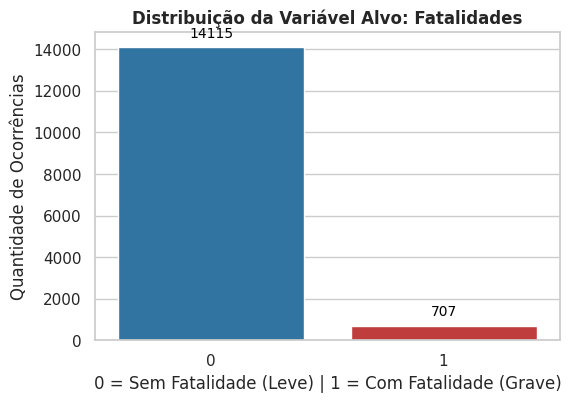

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo visual dos gráficos
sns.set_theme(style="whitegrid")

# 1. Contagem de Valores Nulos (identificação de dados faltantes)
print("--- TOP 10 COLUNAS COM VALORES NULOS ---")
print(X.isnull().sum().sort_values(ascending=False).head(10))
print("\n")

# 2. Distribuição da Variável Alvo (Evidenciando o desbalanceamento)
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=y, hue=y, palette=['#1f77b4', '#d62728'], legend=False)
plt.title('Distribuição da Variável Alvo: Fatalidades', fontsize=12, fontweight='bold')
plt.xlabel('0 = Sem Fatalidade (Leve) | 1 = Com Fatalidade (Grave)')
plt.ylabel('Quantidade de Ocorrências')

# Adição dos rótulos de quantidade acima das barras
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')
plt.show()

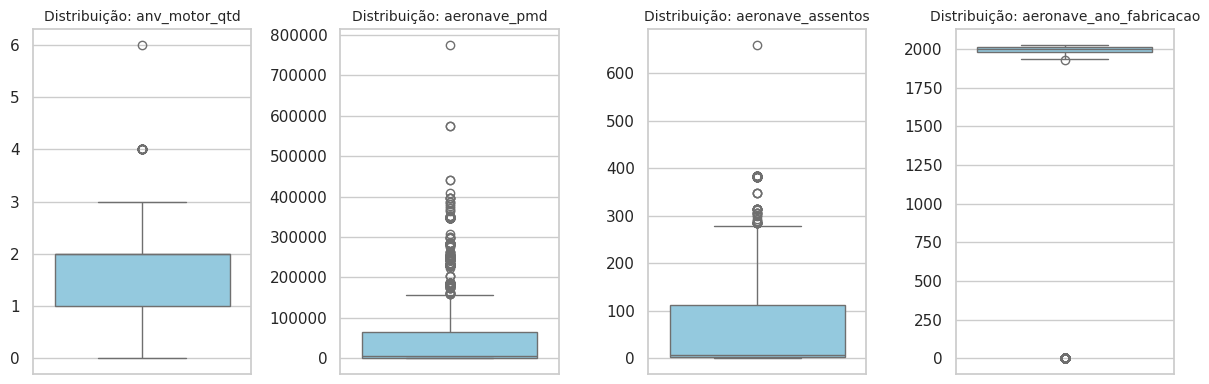

In [8]:
# 3. Identificação de Outliers (Boxplots)
# Plotagem restrita às variáveis numéricas mapeadas na etapa anterior
plt.figure(figsize=(12, 4))

for i, col in enumerate(numeric_features):
    plt.subplot(1, len(numeric_features), i+1)
    sns.boxplot(y=X[col], color='skyblue')
    plt.title(f'Distribuição: {col}', fontsize=10)
    plt.ylabel('')

plt.tight_layout()
plt.show()

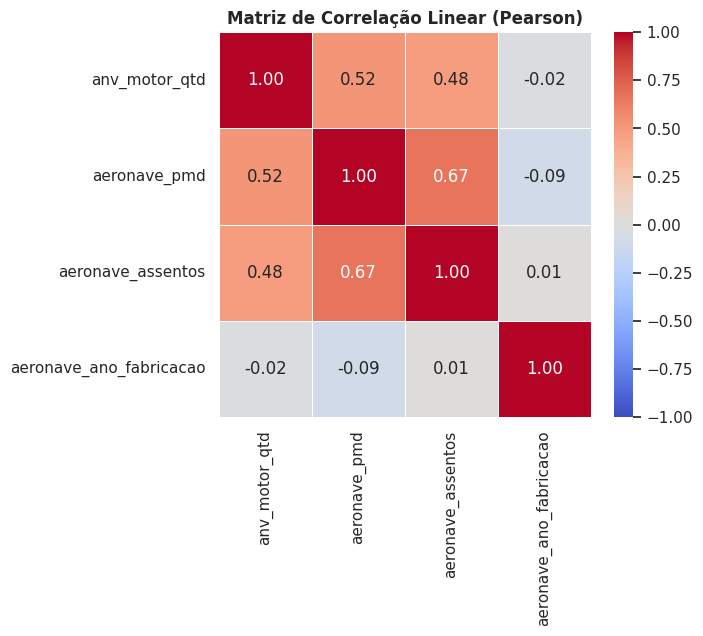

In [9]:
 # 4. Matriz de Correlação (Identificação de Redundâncias)
plt.figure(figsize=(6, 5))

# Cálculo da correlação de Pearson para as variáveis numéricas
correlacao = X[numeric_features].corr()

# Plotagem do mapa de calor (heatmap)
sns.heatmap(correlacao, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlação Linear (Pearson)', fontsize=12, fontweight='bold')
plt.show()

# 2. Pipeline de Pré-processamento e Busca em Grade

O fluxo de preparação e modelagem é encapsulado em um `ImbPipeline` para garantir que a imputação, o escalonamento, a codificação e o balanceamento ocorram exclusivamente dentro de cada partição de treino da validação cruzada.

Configuração do `GridSearchCV`:
* **Validação Cruzada:** 10-fold estratificado (`StratifiedKFold`, `n_splits=10`) executado sobre o conjunto de treino.
* **Grade de Experimentos (384 combinações):** Avaliação combinada de 2 estratégias de imputação numérica (`median`, `mean`), 4 opções de escalonamento (`StandardScaler`, `MinMaxScaler`, `RobustScaler`, sem escalonamento), 2 codificadores categóricos (`OneHotEncoder`, `OrdinalEncoder`), 3 métodos de amostragem (`SMOTE`, `RandomUnderSampler`, sem balanceamento) e 8 faixas de seleção de atributos (`SelectKBest`).
* **Critério de Seleção:** Monitoramento de ROC AUC, F1-score e Acurácia, adotando a métrica ROC AUC (`refit='roc_auc'`) para a seleção do modelo final.

In [10]:
# 3. Construção do Pipeline de Pré-processamento e Modelagem
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_features),
        ('cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_features)
    ])

pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('sampler', 'passthrough'),
    ('feature_selection', SelectKBest(score_func=f_classif)),
    ('classifier', KNeighborsClassifier()) # O kNN utiliza os hiperparâmetros padrão, conforme edital
])

## 2.1 Avaliação do Melhor Modelo

Extração do melhor estimador obtido na busca em grade para avaliação de desempenho:
* Predição sobre o conjunto de teste isolado (`X_test`), gerando a Matriz de Confusão, a Curva ROC e o relatório de métricas por classe.
* Consolidação da média e do desvio-padrão de ROC AUC, F1-score e Acurácia calculados ao longo dos 10 folds da validação cruzada de treino.

In [11]:
import warnings
import pandas as pd
from sklearn.preprocessing import RobustScaler, StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings('ignore')

# 1. Definição do protocolo de validação (10-fold estratificado) NO TREINO
cv_final = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 2. Grade Expandida (> 150 combinações únicas garantidas)
param_grid_final = [
    {
        'preprocessor__num__imputer__strategy': ['median', 'mean'],
        'preprocessor__num__scaler': [StandardScaler(), MinMaxScaler(), RobustScaler(), 'passthrough'],
        'preprocessor__cat__encoder': [OneHotEncoder(handle_unknown='ignore')],
        'sampler': [SMOTE(random_state=42), RandomUnderSampler(random_state=42), 'passthrough'],
        'feature_selection__k': [5, 8, 10, 12, 15, 18, 20, 'all'],
    },
    {
        'preprocessor__num__imputer__strategy': ['median', 'mean'],
        'preprocessor__num__scaler': [StandardScaler(), MinMaxScaler(), RobustScaler(), 'passthrough'],
        'preprocessor__cat__encoder': [OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)],
        'sampler': [SMOTE(random_state=42), RandomUnderSampler(random_state=42), 'passthrough'],
        'feature_selection__k': [2, 3, 4, 5, 6, 7, 8, 'all'],
    }
]
# Total da grade: 2 * 4 * 2 * 3 * 8 = 384 experimentos!

# 3. Configuração da busca em grade
scoring_metrics = ['roc_auc', 'f1', 'accuracy']

grid_search_final = GridSearchCV(
    pipeline,
    param_grid_final,
    cv=cv_final,
    scoring=scoring_metrics,
    refit='roc_auc',
    n_jobs=-1,
    verbose=2
)

# 4. Execução dos experimentos APENAS NO CONJUNTO DE TREINO
print("Executando a grade de 384 experimentos no conjunto de treino...")
grid_search_final.fit(X_train, y_train)

print("\n--- Treinamento Concluído ---")
print("Melhor configuração encontrada:", grid_search_final.best_params_)
print(f"Melhor AUC médio (na validação cruzada): {grid_search_final.best_score_:.4f}")

# 5. Exportação dos resultados detalhados para análise
resultados_finais_df = pd.DataFrame(grid_search_final.cv_results_)
resultados_finais_df.to_csv('resultados_experimentos_knn.csv', index=False)
print("Resultados exportados para 'resultados_experimentos_knn.csv'.")

Executando a grade de 384 experimentos no conjunto de treino...
Fitting 10 folds for each of 384 candidates, totalling 3840 fits

--- Treinamento Concluído ---
Melhor configuração encontrada: {'feature_selection__k': 'all', 'preprocessor__cat__encoder': OneHotEncoder(handle_unknown='ignore'), 'preprocessor__num__imputer__strategy': 'median', 'preprocessor__num__scaler': MinMaxScaler(), 'sampler': RandomUnderSampler(random_state=42)}
Melhor AUC médio (na validação cruzada): 0.8632
Resultados exportados para 'resultados_experimentos_knn.csv'.


Avaliando o melhor modelo no conjunto de teste...


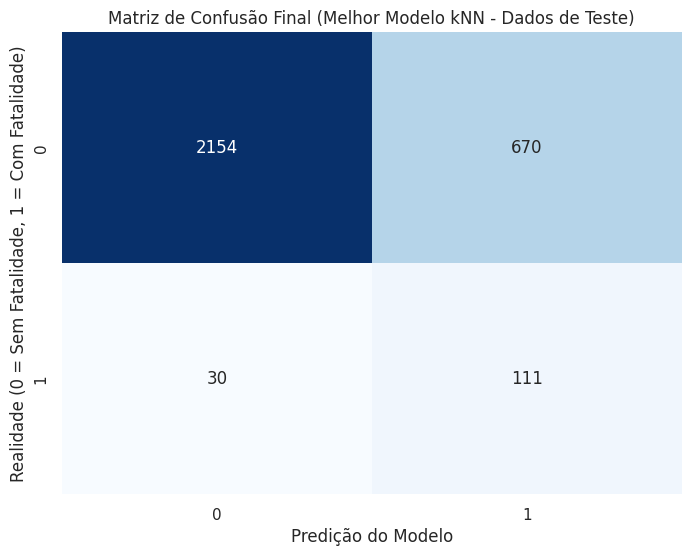

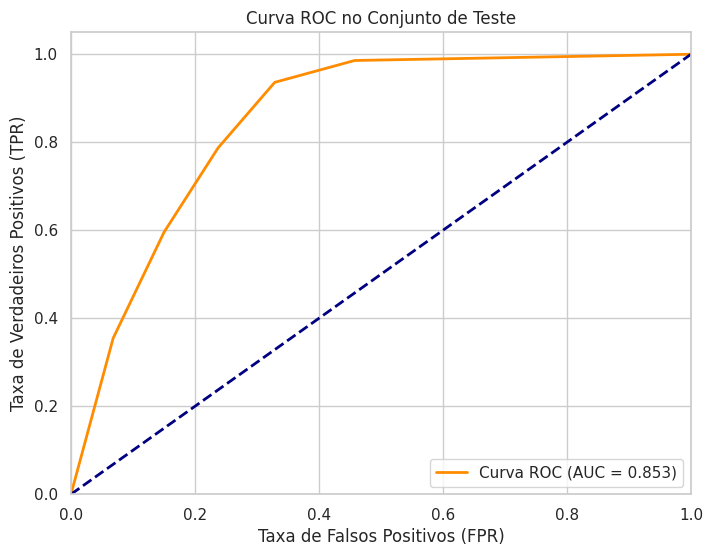


Relatório de Classificação Final (Conjunto de Teste):
              precision    recall  f1-score   support

           0       0.99      0.76      0.86      2824
           1       0.14      0.79      0.24       141

    accuracy                           0.76      2965
   macro avg       0.56      0.77      0.55      2965
weighted avg       0.95      0.76      0.83      2965


--- Desempenho Médio na Validação Cruzada (10-Fold no Treino) ---
ROC AUC : 0.8632 (+/- 0.0190)
F1-Score: 0.2579 (+/- 0.0158)
Acurácia: 0.7568 (+/- 0.0146)


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report

# Extração do melhor modelo otimizado pelo GridSearchCV
melhor_modelo = grid_search_final.best_estimator_

# 1. Geração de predições no CONJUNTO DE TESTE (dados puros, nunca vistos)
print("Avaliando o melhor modelo no conjunto de teste...")
y_pred_test = melhor_modelo.predict(X_test)
y_prob_test = melhor_modelo.predict_proba(X_test)[:, 1]

# 2. Plotagem da Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Matriz de Confusão Final (Melhor Modelo kNN - Dados de Teste)')
plt.xlabel('Predição do Modelo')
plt.ylabel('Realidade (0 = Sem Fatalidade, 1 = Com Fatalidade)')
plt.show()

# 3. Geração das probabilidades para a Curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_test)
roc_auc_score = auc(fpr, tpr)

# Plotagem da Curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC no Conjunto de Teste')
plt.legend(loc="lower right")
plt.show()

# 4. Exibição das métricas complementares finais (Conjunto de Teste)
print("\nRelatório de Classificação Final (Conjunto de Teste):")
print(classification_report(y_test, y_pred_test))

# 5. Exibição da Média e Desvio-Padrão nos 10 Folds de Treino (Exigência do Edital)
idx_melhor = grid_search_final.best_index_
res = grid_search_final.cv_results_

print("\n--- Desempenho Médio na Validação Cruzada (10-Fold no Treino) ---")
print(f"ROC AUC : {res['mean_test_roc_auc'][idx_melhor]:.4f} (+/- {res['std_test_roc_auc'][idx_melhor]:.4f})")
print(f"F1-Score: {res['mean_test_f1'][idx_melhor]:.4f} (+/- {res['std_test_f1'][idx_melhor]:.4f})")
print(f"Acurácia: {res['mean_test_accuracy'][idx_melhor]:.4f} (+/- {res['std_test_accuracy'][idx_melhor]:.4f})")

# 3. Análise de Impacto de Vazamento de Dados (Data Leakage)

Comparação experimental do efeito da variável `aeronave_nivel_dano` sobre a Curva ROC (via validação cruzada de 10 folds):

* **Cenário 1 (Com `aeronave_nivel_dano`):** Inclui o nível de destruição da aeronave, dado registrado apenas após o acidente e que eleva artificialmente a métrica de classificação.
* **Cenário 2 (Sem `aeronave_nivel_dano`):** Remove a informação pós-acidente (nível de dano), utilizando apenas características da aeronave e da operação, o que corresponde à abordagem adotada no modelo principal deste trabalho.

Avaliando Cenário 1 (Com variável 'Nível de Dano' - Triagem de Resgate)...
Avaliando Cenário 2 (Sem variável 'Nível de Dano' - Modelo Principal)...


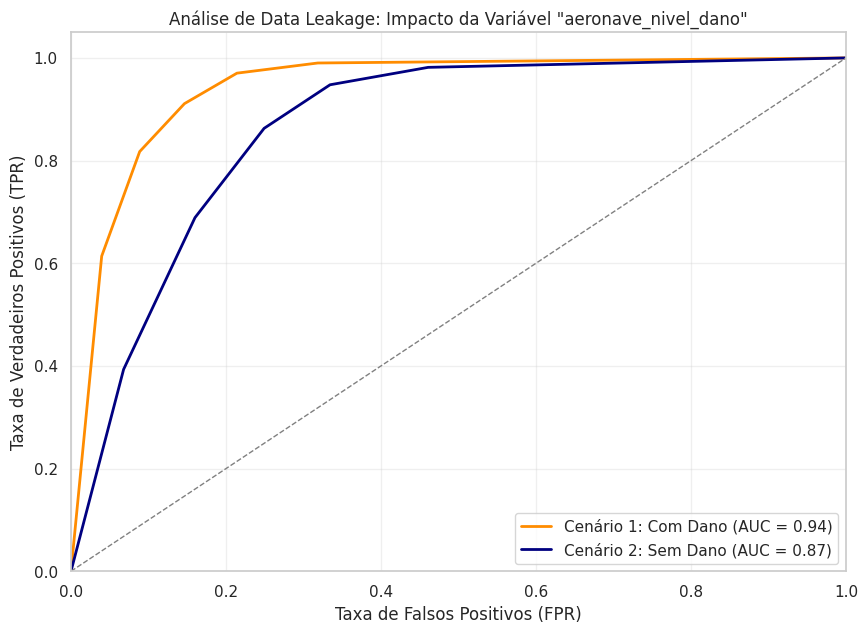

In [13]:
import warnings
warnings.filterwarnings('ignore') # Supressão de avisos matemáticos durante a validação cruzada

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

# 1. Definição das colunas base a serem removidas (ruído e vazamento temporal explícito)
colunas_base = [
    'aeronave_fatalidades_total', 'alvo_fatalidade', 'codigo_ocorrencia2',
    'aeronave_matricula', 'aeronave_modelo', 'aeronave_voo_origem',
    'aeronave_voo_destino', 'aeronave_fabricante', 'aeronave_tipo_icao',
    'aeronave_pais_fabricante', 'aeronave_pais_registro', 'anv_motor_descricao_qtd'
]

# 2. Construção dos DataFrames para análise de impacto (Data Leakage)
X_com_dano = df.drop(columns=colunas_base, errors='ignore')
X_sem_dano = df.drop(columns=colunas_base + ['aeronave_nivel_dano'], errors='ignore')

# 3. Função encapsulada para extração das Curvas ROC (usando a configuração vencedora)
def obter_curva_roc(X_dados):
    num_cols = X_dados.select_dtypes(include=['int64', 'float64']).columns
    cat_cols = X_dados.select_dtypes(include=['object']).columns

    prep = ColumnTransformer(transformers=[
        ('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), ('scaler', MinMaxScaler())]), num_cols),
        ('cat', Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
    ])

    pipe = ImbPipeline(steps=[
        ('preprocessor', prep),
        ('sampler', RandomUnderSampler(random_state=42)),
        ('feature_selection', SelectKBest(score_func=f_classif, k='all')),
        ('classifier', KNeighborsClassifier())
    ])

    # Utilização obrigatória de cv=10 para manter conformidade com o edital
    cv_analise = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    prob = cross_val_predict(pipe, X_dados, y, cv=cv_analise, method='predict_proba')[:, 1]
    return roc_curve(y, prob)

# 4. Avaliação dos cenários
print("Avaliando Cenário 1 (Com variável 'Nível de Dano' - Triagem de Resgate)...")
fpr_com, tpr_com, _ = obter_curva_roc(X_com_dano)
auc_com = auc(fpr_com, tpr_com)

print("Avaliando Cenário 2 (Sem variável 'Nível de Dano' - Modelo Principal)...")
fpr_sem, tpr_sem, _ = obter_curva_roc(X_sem_dano)
auc_sem = auc(fpr_sem, tpr_sem)

# 5. Plotagem comparativa das Curvas ROC
plt.figure(figsize=(10, 7))
plt.plot(fpr_com, tpr_com, color='darkorange', lw=2, label=f'Cenário 1: Com Dano (AUC = {auc_com:.2f})')
plt.plot(fpr_sem, tpr_sem, color='navy', lw=2, label=f'Cenário 2: Sem Dano (AUC = {auc_sem:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Análise de Data Leakage: Impacto da Variável "aeronave_nivel_dano"')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [14]:
from sklearn.metrics import classification_report

# 1. Configuração do pré-processamento para o cenário preventivo
prep_sem = ColumnTransformer(transformers=[
    ('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), X_sem_dano.select_dtypes(include=['int64', 'float64']).columns),
    ('cat', Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))]), X_sem_dano.select_dtypes(include=['object']).columns)
])

# 2. Construção do pipeline com RandomUnderSampler (Foco em manter um alto Recall)
pipe_preventivo = ImbPipeline(steps=[
    ('preprocessor', prep_sem),
    ('sampler', RandomUnderSampler(random_state=42)),
    ('feature_selection', SelectKBest(score_func=f_classif, k='all')),
    ('classifier', KNeighborsClassifier())
])

# 3. Avaliação rigorosa utilizando validação cruzada 10-fold estratificada
cv_preventivo = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
y_pred_sem = cross_val_predict(pipe_preventivo, X_sem_dano, y, cv=cv_preventivo)

# 4. Exibição das métricas
print("\nRelatório do Cenário 2 (Sem Dano - Modelo Principal com Balanceamento):")
print(classification_report(y, y_pred_sem))


Relatório do Cenário 2 (Sem Dano - Modelo Principal com Balanceamento):
              precision    recall  f1-score   support

           0       0.99      0.74      0.85     14115
           1       0.14      0.86      0.25       707

    accuracy                           0.75     14822
   macro avg       0.57      0.80      0.55     14822
weighted avg       0.95      0.75      0.82     14822



# 4. Resultados e Discussão: Análise de Baseline e Trade-off de Métricas

Para avaliar o impacto das técnicas de balanceamento, comparou-se o modelo final (Cenário 2) com um modelo baseline (sem a aplicação do `RandomUnderSampler`).

**Análise de Trade-off (Precisão vs. Recall):**
* **Modelo Baseline (Desbalanceado):** Apresenta alta Acurácia e Precisão devido à predominância de ocorrências não fatais (classe majoritária) na base de dados. Entretanto, o Recall atinge apenas 12%, resultando em uma alta taxa de falsos negativos (falha na detecção de acidentes graves).
* **Modelo Otimizado (Com RandomUnderSampler):** A Precisão é reduzida para cerca de 14%, gerando um volume maior de falsos positivos. Em contrapartida, o Recall sobe para 86%, demonstrando uma capacidade superior de identificar corretamente as ocorrências com fatalidade (classe minoritária).

**Diretriz de Negócio e Risco:**
No contexto de segurança na aviação civil, o custo de um falso negativo (não detectar um risco real de fatalidade) é significativamente maior do que o impacto operacional de um falso positivo (gerar um alerta de risco falso). Portanto, a configuração do modelo prioriza a maximização do Recall, estabelecendo um perfil conservador adequado para triagem e priorização de risco.

In [15]:
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# 1. Recuperação dos dados processados (remoção de ruídos e prevenção de data leakage)
colunas_base = [
    'aeronave_fatalidades_total', 'alvo_fatalidade', 'codigo_ocorrencia2',
    'aeronave_matricula', 'aeronave_modelo', 'aeronave_voo_origem',
    'aeronave_voo_destino', 'aeronave_fabricante', 'aeronave_tipo_icao',
    'aeronave_pais_fabricante', 'aeronave_pais_registro', 'anv_motor_descricao_qtd'
]

X_sem_dano = df.drop(columns=colunas_base + ['aeronave_nivel_dano'], errors='ignore')
y = df['alvo_fatalidade']

num_cols_sem = X_sem_dano.select_dtypes(include=['int64', 'float64']).columns
cat_cols_sem = X_sem_dano.select_dtypes(include=['object']).columns

prep_sem = ColumnTransformer(transformers=[
    ('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols_sem),
    ('cat', Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))]), cat_cols_sem)
])

# 2. Pipeline Baseline Puro (Sem estratégias de balanceamento de classes)
pipe_puro = Pipeline(steps=[
    ('preprocessor', prep_sem),
    ('feature_selection', SelectKBest(score_func=f_classif, k='all')),
    ('classifier', KNeighborsClassifier())
])

# 3. Avaliação rigorosa utilizando validação cruzada 10-fold estratificada
cv_puro = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

print("Avaliando Cenário 3 (Modelo Baseline: Sem Dano e Sem Balanceamento)...")
y_pred_puro = cross_val_predict(pipe_puro, X_sem_dano, y, cv=cv_puro)

# 4. Exibição das métricas para comparação do impacto no Recall
print("\nRelatório do Cenário 3 (Baseline Puro):")
print(classification_report(y, y_pred_puro))

Avaliando Cenário 3 (Modelo Baseline: Sem Dano e Sem Balanceamento)...

Relatório do Cenário 3 (Baseline Puro):
              precision    recall  f1-score   support

           0       0.96      0.99      0.97     14115
           1       0.36      0.12      0.18       707

    accuracy                           0.95     14822
   macro avg       0.66      0.55      0.58     14822
weighted avg       0.93      0.95      0.94     14822



In [16]:
from sklearn.model_selection import cross_validate

metricas = ['roc_auc', 'f1', 'accuracy', 'precision', 'recall']

def resumo(nome, modelo, X_, y_):
    s = cross_validate(modelo, X_, y_, cv=cv_final, scoring=metricas)
    print(f"\n--- {nome} ---")
    for m in metricas:
        v = s[f'test_{m}']
        print(f"{m.upper()}: {v.mean():.4f} (+/- {v.std():.4f})")

resumo("Melhor modelo da grade (sem dano)", melhor_modelo, X, y)
resumo("Cenário 2: sem nivel_dano + undersampling", pipe_preventivo, X_sem_dano, y)
resumo("Cenário 3: baseline sem balanceamento", pipe_puro, X_sem_dano, y)


--- Melhor modelo da grade (sem dano) ---
ROC_AUC: 0.8661 (+/- 0.0119)
F1: 0.2525 (+/- 0.0093)
ACCURACY: 0.7562 (+/- 0.0114)
PRECISION: 0.1480 (+/- 0.0059)
RECALL: 0.8629 (+/- 0.0356)

--- Cenário 2: sem nivel_dano + undersampling ---
ROC_AUC: 0.8627 (+/- 0.0144)
F1: 0.2455 (+/- 0.0143)
ACCURACY: 0.7477 (+/- 0.0135)
PRECISION: 0.1432 (+/- 0.0090)
RECALL: 0.8586 (+/- 0.0413)

--- Cenário 3: baseline sem balanceamento ---
ROC_AUC: 0.7451 (+/- 0.0406)
F1: 0.1784 (+/- 0.0291)
ACCURACY: 0.9480 (+/- 0.0019)
PRECISION: 0.3635 (+/- 0.0521)
RECALL: 0.1188 (+/- 0.0220)


# 5. Conclusão

A partir da avaliação das métricas, o Cenário 2 (Modelo sem nível de dano, com RandomUnderSampler) foi selecionado como a solução mais alinhada aos objetivos do projeto. Embora a Precisão seja reduzida para aproximadamente 14%, o modelo atinge um Recall de 86% na identificação da classe minoritária (ocorrências com fatalidade).

Para a regra de negócio do setor aéreo, esse trade-off atende ao requisito principal de segurança: minimizar falsos negativos (riscos não detectados), tolerando um volume maior de falsos positivos (alertas de risco). A análise detalhada sobre custo computacional, interpretabilidade do algoritmo kNN e validação da robustez do pipeline encontra-se documentada no Relatório Final (PDF).

Ressalva: o modelo selecionado usa `aeronave_fase_operacao`, informação conhecida apenas durante o voo. Por isso, ele serve à análise retrospectiva e à priorização de investigações. Para avaliações estritamente preventivas (pré-voo), deve-se usar a versão sem essa variável (AUC de teste 0,80), conforme o relatório.

# 6. Análises complementares

Nesta parte, serão feitas algumas análises adicionais para avaliar melhor os resultados do modelo. Também serão comparadas as técnicas de pré-processamento, as métricas obtidas em cada fold e os resultados no conjunto de teste.

Além disso, serão analisados o tempo de execução, a robustez e a importância dos atributos utilizados. Os gráficos gerados serão salvos na pasta `figuras/` para serem utilizados no relatório.

## 6.2 Número real de configurações únicas
Com `OrdinalEncoder` o número de colunas é pequeno; valores de `k` maiores que esse número (e `'all'`) produzem o mesmo conjunto de atributos. Aqui contamos quantas das 384 configurações são realmente distintas.

In [17]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import (roc_auc_score, roc_curve, f1_score, accuracy_score, precision_score,
                             recall_score, confusion_matrix, average_precision_score, precision_recall_curve)
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

os.makedirs('figuras', exist_ok=True)
sns.set_theme(style='whitegrid')

usadas = list(numeric_features) + list(categorical_features)
ignoradas = [c for c in X.columns if c not in usadas]
print(f"Colunas no CSV original: {df.shape[1]} | Instâncias: {df.shape[0]}")
print(f"Preditores efetivamente usados: {len(usadas)}")
print("  numéricos   :", list(numeric_features))
print("  categóricos :", list(categorical_features))
print("Preditores em X IGNORADOS pelo ColumnTransformer:", ignoradas)
print()
print(X.dtypes)

Colunas no CSV original: 21 | Instâncias: 14822
Preditores efetivamente usados: 8
  numéricos   : ['anv_motor_qtd', 'aeronave_pmd', 'aeronave_assentos', 'aeronave_ano_fabricacao']
  categóricos : ['aeronave_tipo_equipamento', 'aeronave_motor_tipo', 'aeronave_fase_operacao', 'aeronave_tipo_operacao']
Preditores em X IGNORADOS pelo ColumnTransformer: []

aeronave_tipo_equipamento     object
aeronave_motor_tipo           object
anv_motor_qtd                float64
aeronave_pmd                 float64
aeronave_assentos            float64
aeronave_ano_fabricacao      float64
aeronave_fase_operacao        object
aeronave_tipo_operacao        object
dtype: object


In [18]:
res = pd.DataFrame(grid_search_final.cv_results_)

def nome(o):
    return o if isinstance(o, str) else type(o).__name__

res['imputacao']     = res['param_preprocessor__num__imputer__strategy'].astype(str)
res['escalonamento'] = res['param_preprocessor__num__scaler'].apply(nome)
res['encoding']      = res['param_preprocessor__cat__encoder'].apply(nome)
res['balanceamento'] = res['param_sampler'].apply(nome)
res['k']             = res['param_feature_selection__k']

def n_features(encoder):
    prep = clone(pipeline.named_steps['preprocessor'])
    prep.set_params(cat__encoder=encoder)
    return prep.fit_transform(X_train).shape[1]

nf = {
    'OneHotEncoder':  n_features(OneHotEncoder(handle_unknown='ignore')),
    'OrdinalEncoder': n_features(OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
}
print("Nº de colunas após o encoding:", nf)

res['k_efetivo'] = res.apply(
    lambda r: nf[r['encoding']] if r['k'] == 'all' else min(int(r['k']), nf[r['encoding']]), axis=1)

chave = ['imputacao', 'escalonamento', 'encoding', 'balanceamento', 'k_efetivo']
res_unico = res.drop_duplicates(chave).copy()
print(f"\nConfigurações na grade: {len(res)}  |  configurações realmente distintas: {len(res_unico)}")
print("O mínimo do edital (150) foi atingido?", len(res_unico) >= 150)

Nº de colunas após o encoding: {'OneHotEncoder': 71, 'OrdinalEncoder': 8}

Configurações na grade: 384  |  configurações realmente distintas: 360
O mínimo do edital (150) foi atingido? True


## 6.3 Influência das técnicas de pré-processamento

Nesta análise, vamos avaliar como cada técnica de pré-processamento influencia os resultados do modelo. Para isso, serão comparadas as médias de AUC de cada opção, além da diferença entre os resultados e do valor de η² (eta ao quadrado).

Com esses dados, será possível identificar quais etapas, como o balanceamento e o encoding, tiveram maior influência no desempenho.

Impacto de cada fator sobre o AUC (CV 10-fold no treino):


,amplitude_AUC,eta2
balanceamento,0.0983,0.5133
k_efetivo,0.1182,0.3280
encoding,0.0316,0.0790
escalonamento,0.0130,0.0088
imputacao,0.0010,0.0001



--- imputacao ---


,mean_test_roc_auc,mean_test_f1,mean_test_accuracy
imputacao,,,
mean,0.7413,0.1833,0.8558
median,0.7424,0.1852,0.8554



--- escalonamento ---


,mean_test_roc_auc,mean_test_f1,mean_test_accuracy
escalonamento,,,
MinMaxScaler,0.7450,0.1897,0.8643
RobustScaler,0.7458,0.1903,0.8611
StandardScaler,0.7437,0.1881,0.8589
passthrough,0.7328,0.1689,0.8382


... (2 outputs left out)


--- balanceamento ---


,mean_test_roc_auc,mean_test_f1,mean_test_accuracy
balanceamento,,,
RandomUnderSampler,0.7912,0.2045,0.7303
SMOTE,0.7413,0.2300,0.8878
passthrough,0.6930,0.1183,0.9488



--- k_efetivo ---


,mean_test_roc_auc,mean_test_f1,mean_test_accuracy
k_efetivo,,,
2,0.6676,0.1220,0.9022
3,0.6961,0.1494,0.8834
4,0.7028,0.1611,0.8856
5,0.7229,0.1483,0.8420
6,0.7531,0.1969,0.8621
7,0.7647,0.2033,0.8610
8,0.7520,0.1909,0.8375
10,0.7444,0.1849,0.8400
12,0.7482,0.1924,0.8441


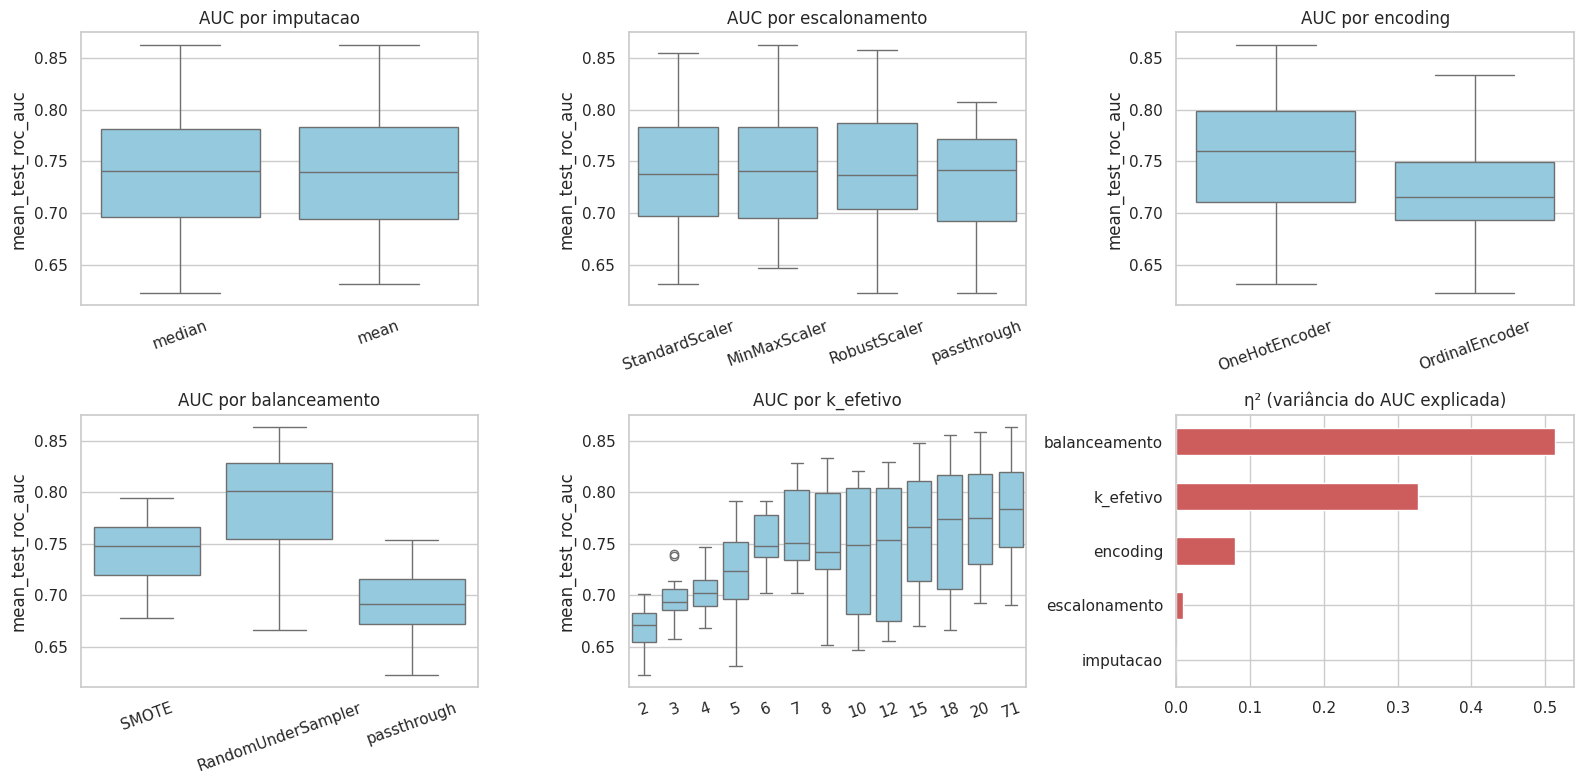

In [19]:
met = 'mean_test_roc_auc'
fatores = ['imputacao', 'escalonamento', 'encoding', 'balanceamento', 'k_efetivo']

def eta2(d, fator, col):
    gm = d[col].mean()
    ss_b = d.groupby(fator)[col].apply(lambda s: len(s) * (s.mean() - gm) ** 2).sum()
    ss_t = ((d[col] - gm) ** 2).sum()
    return ss_b / ss_t

resumo_fatores = pd.DataFrame({
    'amplitude_AUC': [res_unico.groupby(f)[met].mean().max() - res_unico.groupby(f)[met].mean().min() for f in fatores],
    'eta2':          [eta2(res_unico, f, met) for f in fatores],
}, index=fatores).sort_values('eta2', ascending=False)
print("Impacto de cada fator sobre o AUC (CV 10-fold no treino):")
display(resumo_fatores.round(4))

for f in fatores:
    print(f"\n--- {f} ---")
    display(res_unico.groupby(f)[[met, 'mean_test_f1', 'mean_test_accuracy']].mean().round(4))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, f in zip(axes.ravel(), fatores):
    sns.boxplot(data=res_unico, x=f, y=met, ax=ax, color='skyblue')
    ax.set_title(f'AUC por {f}'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
resumo_fatores['eta2'].plot.barh(ax=axes.ravel()[-1], color='indianred')
axes.ravel()[-1].set_title('η² (variância do AUC explicada)'); axes.ravel()[-1].invert_yaxis()
plt.tight_layout(); plt.savefig('figuras/impacto_fatores.png', dpi=200); plt.show()

## 6.4 Top-10 configurações e custo computacional

In [20]:
cols = ['imputacao', 'escalonamento', 'encoding', 'balanceamento', 'k_efetivo',
        'mean_test_roc_auc', 'std_test_roc_auc', 'mean_test_f1', 'std_test_f1',
        'mean_test_accuracy', 'std_test_accuracy', 'mean_fit_time', 'mean_score_time']
top10 = res_unico.sort_values(met, ascending=False).head(10)[cols]
display(top10.round(4))
res_unico[cols].sort_values(met, ascending=False).to_csv('tabela_experimentos_completa.csv', index=False)

print("\nCusto computacional médio por técnica (segundos por fold):")
for f in ['balanceamento', 'encoding', 'k_efetivo']:
    display(res_unico.groupby(f)[['mean_fit_time', 'mean_score_time']].mean().round(4))

,imputacao,escalonamento,encoding,balanceamento,k_efetivo,mean_test_roc_auc,std_test_roc_auc,mean_test_f1,std_test_f1,mean_test_accuracy,std_test_accuracy,mean_fit_time,mean_score_time
172,median,MinMaxScaler,OneHotEncoder,RandomUnderSampler,71,0.8632,0.0190,0.2579,0.0158,0.7568,0.0146,0.0786,0.1945
184,mean,MinMaxScaler,OneHotEncoder,RandomUnderSampler,71,0.8631,0.0187,0.2574,0.0160,0.7577,0.0139,0.0687,0.1850
160,mean,MinMaxScaler,OneHotEncoder,RandomUnderSampler,20,0.8580,0.0230,0.2469,0.0139,0.7468,0.0168,0.1074,0.2166
175,median,RobustScaler,OneHotEncoder,RandomUnderSampler,71,0.8578,0.0201,0.2471,0.0155,0.7503,0.0147,0.0872,0.1937
187,mean,RobustScaler,OneHotEncoder,RandomUnderSampler,71,0.8565,0.0196,0.2467,0.0162,0.7518,0.0152,0.0882,0.1779
127,median,RobustScaler,OneHotEncoder,RandomUnderSampler,18,0.8554,0.0191,0.2408,0.0116,0.7348,0.0163,0.0871,0.1703
181,mean,StandardScaler,OneHotEncoder,RandomUnderSampler,71,0.8553,0.0206,0.2440,0.0177,0.7464,0.0130,0.0726,0.1938
148,median,MinMaxScaler,OneHotEncoder,RandomUnderSampler,20,0.8549,0.0202,0.2466,0.0124,0.7478,0.0149,0.1436,0.2857
169,median,StandardScaler,OneHotEncoder,RandomUnderSampler,71,0.8548,0.0192,0.2457,0.0159,0.7461,0.0140,0.0880,0.1895
124,median,MinMaxScaler,OneHotEncoder,RandomUnderSampler,18,0.8534,0.0199,0.2497,0.0122,0.7491,0.0178,0.0751,0.1744



Custo computacional médio por técnica (segundos por fold):


,mean_fit_time,mean_score_time
balanceamento,,
RandomUnderSampler,0.0884,0.1483
SMOTE,0.1284,1.9774
passthrough,0.0891,1.0545


,mean_fit_time,mean_score_time
encoding,,
OneHotEncoder,0.1084,1.8870
OrdinalEncoder,0.0946,0.1151


,mean_fit_time,mean_score_time
k_efetivo,,
2,0.0866,0.1522
3,0.0913,0.1041
4,0.0916,0.1183
5,0.1202,0.9911
6,0.0989,0.1021
7,0.0969,0.1036
8,0.1001,0.9479
10,0.1056,1.9308
12,0.1074,1.8553


## 6.5 Métricas média ± desvio por fold, matriz de confusão média e ROC média


Melhor modelo — 10-fold estratificado no treino (média e desvio-padrão):


,mean,std
AUC,0.8632,0.0200
F1,0.2579,0.0166
Acurácia,0.7568,0.0154
Precisão,0.1510,0.0105
Recall,0.8832,0.0446


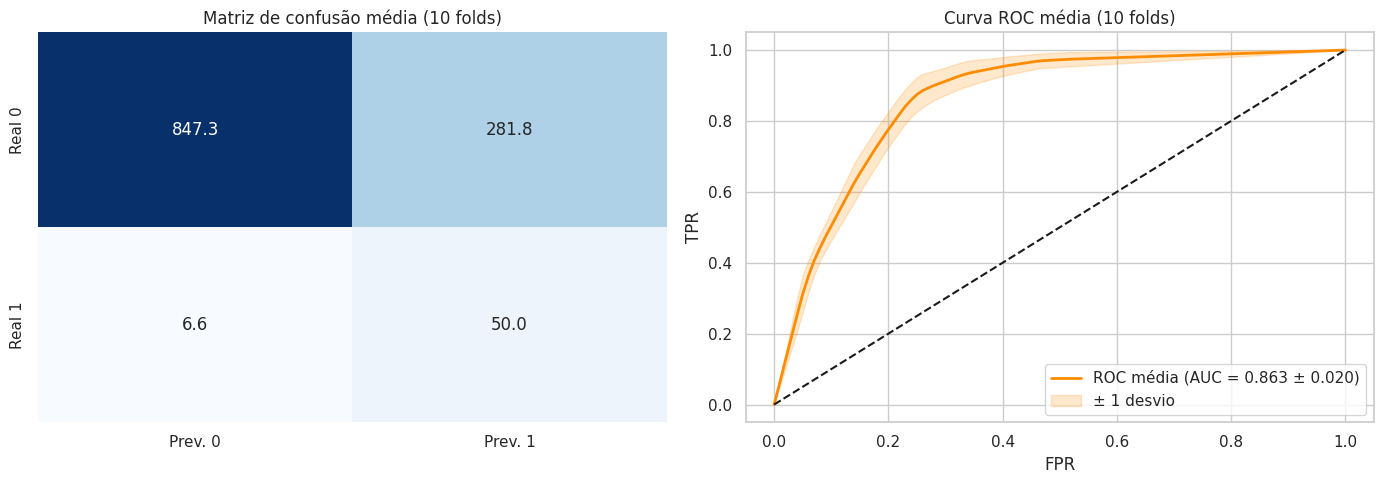

In [21]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
rows, cms, tprs = [], [], []
fpr_grid = np.linspace(0, 1, 101)

for tr, va in cv10.split(X_train, y_train):
    m = clone(melhor_modelo)
    m.fit(X_train.iloc[tr], y_train.iloc[tr])
    yv = y_train.iloc[va]
    p = m.predict_proba(X_train.iloc[va])[:, 1]
    yh = m.predict(X_train.iloc[va])
    rows.append(dict(AUC=roc_auc_score(yv, p), F1=f1_score(yv, yh), Acurácia=accuracy_score(yv, yh),
                     Precisão=precision_score(yv, yh), Recall=recall_score(yv, yh)))
    cms.append(confusion_matrix(yv, yh))
    f_, t_, _ = roc_curve(yv, p); tprs.append(np.interp(fpr_grid, f_, t_))

folds_df = pd.DataFrame(rows)
tabela_cv = folds_df.agg(['mean', 'std']).T.round(4)
print("Melhor modelo — 10-fold estratificado no treino (média e desvio-padrão):")
display(tabela_cv)

cm_medio = np.mean(cms, axis=0)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm_medio, annot=True, fmt='.1f', cmap='Blues', cbar=False, ax=ax[0],
            xticklabels=['Prev. 0', 'Prev. 1'], yticklabels=['Real 0', 'Real 1'])
ax[0].set_title('Matriz de confusão média (10 folds)')
tpr_m, tpr_s = np.mean(tprs, axis=0), np.std(tprs, axis=0)
ax[1].plot(fpr_grid, tpr_m, color='darkorange', lw=2, label=f"ROC média (AUC = {folds_df['AUC'].mean():.3f} ± {folds_df['AUC'].std():.3f})")
ax[1].fill_between(fpr_grid, np.clip(tpr_m - tpr_s, 0, 1), np.clip(tpr_m + tpr_s, 0, 1), alpha=0.2, color='darkorange', label='± 1 desvio')
ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].set_xlabel('FPR'); ax[1].set_ylabel('TPR'); ax[1].legend(loc='lower right')
ax[1].set_title('Curva ROC média (10 folds)')
plt.tight_layout(); plt.savefig('figuras/cv_confusao_roc.png', dpi=200); plt.show()

## 6.6 Comparação dos modelos no conjunto de teste
Para uma comparação justa, o AUC do hold-out (0,852) foi comparado com o resultado do baseline na validação cruzada (0,74). Porém, esses valores foram obtidos em avaliações diferentes.

Para fazer uma comparação mais adequada, os modelos foram treinados utilizando a mesma base de treino e avaliados no mesmo conjunto de teste. Foram considerados o melhor modelo encontrado, o baseline sem balanceamento, o SMOTE e um classificador aleatório.

Além do AUC, também foram utilizadas as métricas PR-AUC e lift, considerando que apenas 4,8% dos registros pertencem à classe positiva.

In [22]:
from imblearn.over_sampling import SMOTE

variantes = {
    'Melhor (undersampling)': clone(melhor_modelo),
    'Sem balanceamento':      clone(melhor_modelo).set_params(sampler='passthrough'),
    'SMOTE':                  clone(melhor_modelo).set_params(sampler=SMOTE(random_state=42)),
}
prev = y_test.mean()
linhas, probs = [], {}
for nome_v, mdl in variantes.items():
    mdl.fit(X_train, y_train)
    p = mdl.predict_proba(X_test)[:, 1]; yh = mdl.predict(X_test); probs[nome_v] = p
    prec = precision_score(y_test, yh)
    linhas.append({'Modelo': nome_v, 'AUC': roc_auc_score(y_test, p), 'PR-AUC': average_precision_score(y_test, p),
                   'Precisão': prec, 'Recall': recall_score(y_test, yh), 'F1': f1_score(y_test, yh),
                   'Acurácia': accuracy_score(y_test, yh), '% sinalizado': yh.mean(), 'Lift (prec/prevalência)': prec / prev})
linhas.append({'Modelo': 'Aleatório (referência)', 'AUC': 0.5, 'PR-AUC': prev, 'Precisão': prev, 'Recall': np.nan,
               'F1': np.nan, 'Acurácia': np.nan, '% sinalizado': np.nan, 'Lift (prec/prevalência)': 1.0})
comparacao = pd.DataFrame(linhas).set_index('Modelo').round(3)
print(f"Prevalência de fatalidades no teste: {prev:.3%}")
display(comparacao)

# Intervalo de confiança (bootstrap) para o AUC do melhor modelo no teste
rng = np.random.default_rng(42); yt = y_test.values; pb = probs['Melhor (undersampling)']; aucs = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].min() == yt[idx].max(): continue
    aucs.append(roc_auc_score(yt[idx], pb[idx]))
print(f"AUC no teste: {roc_auc_score(yt, pb):.3f}  IC95% bootstrap: [{np.percentile(aucs, 2.5):.3f}, {np.percentile(aucs, 97.5):.3f}]")

Prevalência de fatalidades no teste: 4.755%


,AUC,PR-AUC,Precisão,Recall,F1,Acurácia,% sinalizado,Lift (prec/prevalência)
Modelo,,,,,,,,
Melhor (undersampling),0.853,0.164,0.142,0.787,0.241,0.764,0.263,2.989
Sem balanceamento,0.735,0.160,0.364,0.113,0.173,0.948,0.015,7.647
SMOTE,0.757,0.136,0.160,0.482,0.240,0.855,0.143,3.365
Aleatório (referência),0.500,0.048,0.048,NaN,NaN,NaN,NaN,1.000


AUC no teste: 0.853  IC95% bootstrap: [0.830, 0.874]


## 6.7 Relação entre recall e falsos positivos

Um recall mais alto permite identificar uma parcela maior dos casos positivos, mas também pode aumentar o número de falsos positivos.

Por isso, vamos analisar quantos voos seriam sinalizados pelo modelo em diferentes níveis de recall. Assim, será possível avaliar melhor o impacto dessa escolha na prática.

,limiar,recall,precisão,% sinalizado,lift
0,0.2,0.986,0.097,0.483,2.043
1,0.4,0.936,0.125,0.358,2.619
2,0.6,0.787,0.142,0.263,2.989
3,0.8,0.596,0.165,0.171,3.477
4,1.0,0.355,0.207,0.082,4.345


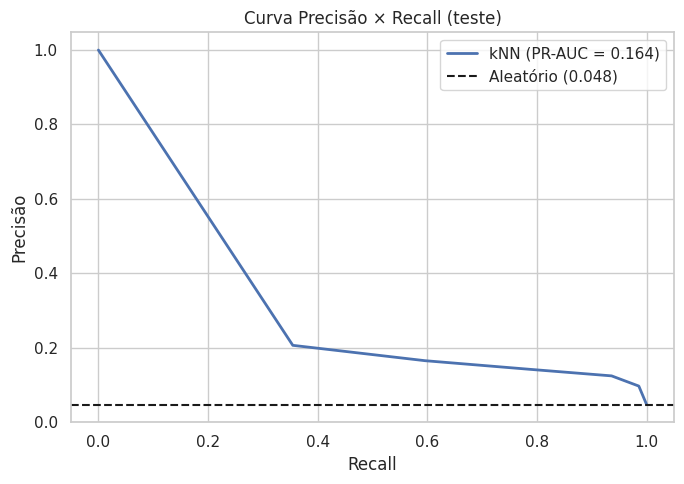

In [23]:
p = probs['Melhor (undersampling)']
linhas = []
for thr in np.unique(np.round(p, 3)):
    if thr == 0: continue
    yh = (p >= thr).astype(int)
    if yh.sum() == 0: continue
    linhas.append({'limiar': thr, 'recall': recall_score(y_test, yh), 'precisão': precision_score(y_test, yh),
                   '% sinalizado': yh.mean(), 'lift': precision_score(y_test, yh) / prev})
operacao = pd.DataFrame(linhas).round(3)
display(operacao)

prec_c, rec_c, _ = precision_recall_curve(y_test, p)
plt.figure(figsize=(7, 5))
plt.plot(rec_c, prec_c, lw=2, label=f'kNN (PR-AUC = {average_precision_score(y_test, p):.3f})')
plt.axhline(prev, color='k', ls='--', label=f'Aleatório ({prev:.3f})')
plt.xlabel('Recall'); plt.ylabel('Precisão'); plt.title('Curva Precisão × Recall (teste)'); plt.legend()
plt.tight_layout(); plt.savefig('figuras/pr_curve.png', dpi=200); plt.show()

## 6.8 Interpretabilidade: importância por permutação
O kNN não tem coeficientes. A importância por permutação mede quanto o AUC no teste cai quando embaralhamos cada atributo original.

,queda_AUC,desvio
aeronave_fase_operacao,0.0853,0.0105
aeronave_tipo_operacao,0.0361,0.0088
aeronave_motor_tipo,0.0245,0.0100
aeronave_ano_fabricacao,0.0005,0.0059
aeronave_tipo_equipamento,-0.0004,0.0017
aeronave_assentos,-0.0026,0.0036
aeronave_pmd,-0.0053,0.0040
anv_motor_qtd,-0.0083,0.0046


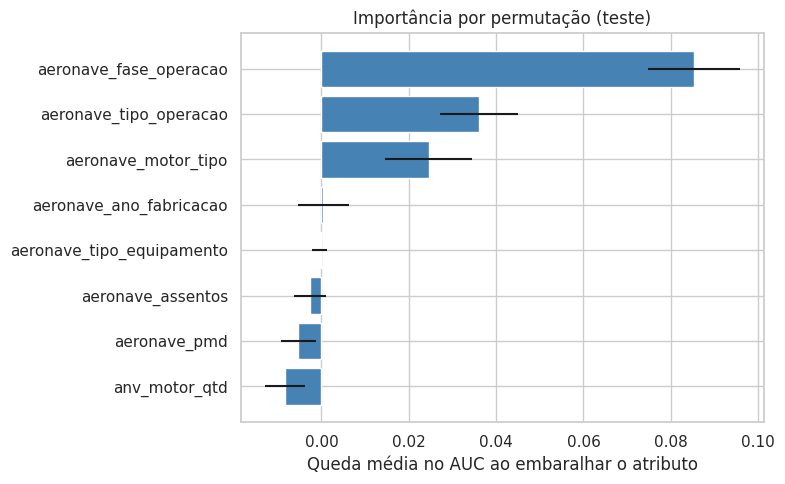

In [24]:
pi = permutation_importance(melhor_modelo, X_test, y_test, scoring='roc_auc',
                            n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.DataFrame({'queda_AUC': pi.importances_mean, 'desvio': pi.importances_std}, index=X_test.columns).sort_values('queda_AUC')
display(imp.sort_values('queda_AUC', ascending=False).round(4))
plt.figure(figsize=(8, 5))
plt.barh(imp.index, imp['queda_AUC'], xerr=imp['desvio'], color='steelblue')
plt.xlabel('Queda média no AUC ao embaralhar o atributo'); plt.title('Importância por permutação (teste)')
plt.tight_layout(); plt.savefig('figuras/importancia_permutacao.png', dpi=200); plt.show()

## 6.9 Robustez: CV repetida com sementes diferentes
Verifica se o ganho do balanceamento é estável ou depende de uma partição de sorte (3 repetições de 10-fold).

In [25]:
rcv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=7)
saida = {}
for nome_v in ['Melhor (undersampling)', 'Sem balanceamento']:
    s = cross_validate(variantes[nome_v], X_train, y_train, cv=rcv, scoring=['roc_auc', 'recall', 'f1'], n_jobs=-1)
    saida[nome_v] = {m: f"{s['test_' + m].mean():.3f} ± {s['test_' + m].std():.3f}" for m in ['roc_auc', 'recall', 'f1']}
display(pd.DataFrame(saida).T)

,roc_auc,recall,f1
Melhor (undersampling),0.864 ± 0.017,0.861 ± 0.041,0.259 ± 0.013
Sem balanceamento,0.750 ± 0.032,0.134 ± 0.046,0.196 ± 0.061


# 7. Análises adicionais e validação do modelo

Nesta etapa, serão realizadas outras análises para verificar possíveis limitações do modelo e avaliar melhor os resultados obtidos.

Serão investigados o uso da variável `fase_operacao`, a presença de aeronaves do mesmo acidente nos conjuntos de treino e teste e a influência da variável `nivel_dano`. Também serão realizados testes estatísticos para avaliar o balanceamento, verificar a estabilidade dos resultados e comparar o kNN com outros modelos.

As análises utilizam os dados e o melhor modelo definidos na seção anterior. Portanto, execute esta parte após concluir a seção 6.

## 7.1 Avaliação do uso da variável `aeronave_fase_operacao`

A variável `aeronave_fase_operacao` indica em qual etapa do voo ocorreu o acidente, como decolagem, cruzeiro ou pouso. Como essa informação só é conhecida durante ou após a ocorrência, seu uso pode limitar a aplicação do modelo em previsões feitas antes do voo.

Além disso, essa variável apresentou a maior importância na análise por permutação. Por isso, vamos comparar o desempenho do modelo completo com outras duas versões: uma sem `aeronave_fase_operacao` e outra sem essa variável e também sem `tipo_operacao`.

Para manter a comparação, será utilizada a mesma configuração de parâmetros encontrada na busca anterior.

In [26]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, precision_score
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

print("Configuração vencedora da grade:", grid_search_final.best_params_)
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

def montar(num_cols, cat_cols, sampler=None, seed=42):
    prep = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', MinMaxScaler())]), list(num_cols)),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('encoder', OneHotEncoder(handle_unknown='ignore'))]), list(cat_cols))])
    return ImbPipeline([('preprocessor', prep),
                        ('sampler', sampler if sampler is not None else RandomUnderSampler(random_state=seed)),
                        ('feature_selection', SelectKBest(f_classif, k='all')),
                        ('classifier', KNeighborsClassifier())])

def avaliar(nome, num_cols, cat_cols, Xtr, Xte, ytr=None, yte=None):
    ytr = y_train if ytr is None else ytr
    yte = y_test if yte is None else yte
    pipe = montar(num_cols, cat_cols)
    cvs = cross_validate(pipe, Xtr, ytr, cv=cv10, scoring=['roc_auc', 'recall'], n_jobs=-1)
    pipe.fit(Xtr, ytr)
    p = pipe.predict_proba(Xte)[:, 1]; yh = pipe.predict(Xte)
    return {'Modelo': nome, 'nº atributos': len(num_cols) + len(cat_cols),
            'AUC (CV treino)': f"{cvs['test_roc_auc'].mean():.3f} ± {cvs['test_roc_auc'].std():.3f}",
            'Recall (CV treino)': f"{cvs['test_recall'].mean():.3f} ± {cvs['test_recall'].std():.3f}",
            'AUC (teste)': round(roc_auc_score(yte, p), 3), 'PR-AUC (teste)': round(average_precision_score(yte, p), 3),
            'Recall (teste)': round(recall_score(yte, yh), 3), 'Precisão (teste)': round(precision_score(yte, yh), 3),
            '% sinalizado': round(yh.mean(), 3)}

num0, cat0 = list(numeric_features), list(categorical_features)
cat_sem_fase = [c for c in cat0 if c != 'aeronave_fase_operacao']
cat_sem_fase_tipo = [c for c in cat_sem_fase if c != 'aeronave_tipo_operacao']

ablacao = pd.DataFrame([
    avaliar('Completo (8 atributos)', num0, cat0, X_train, X_test),
    avaliar('Sem fase_operacao', num0, cat_sem_fase, X_train, X_test),
    avaliar('Sem fase_operacao e tipo_operacao', num0, cat_sem_fase_tipo, X_train, X_test),
]).set_index('Modelo')
display(ablacao)
ablacao.to_csv('ablacao_fase_operacao.csv')

Configuração vencedora da grade: {'feature_selection__k': 'all', 'preprocessor__cat__encoder': OneHotEncoder(handle_unknown='ignore'), 'preprocessor__num__imputer__strategy': 'median', 'preprocessor__num__scaler': MinMaxScaler(), 'sampler': RandomUnderSampler(random_state=42)}


,nº atributos,AUC (CV treino),Recall (CV treino),AUC (teste),PR-AUC (teste),Recall (teste),Precisão (teste),% sinalizado
Modelo,,,,,,,,
Completo (8 atributos),8,0.863 ± 0.019,0.883 ± 0.042,0.853,0.164,0.787,0.142,0.263
Sem fase_operacao,7,0.809 ± 0.031,0.806 ± 0.049,0.800,0.122,0.780,0.113,0.329
Sem fase_operacao e tipo_operacao,6,0.806 ± 0.031,0.818 ± 0.058,0.776,0.107,0.759,0.106,0.341


## 7.2 Verificação de acidentes com mais de uma aeronave

Um mesmo acidente pode envolver várias aeronaves, que podem apresentar características semelhantes. Quando aeronaves do mesmo acidente são separadas entre os conjuntos de treino e teste, existe o risco de o modelo obter uma vantagem por já ter encontrado informações semelhantes durante o treinamento.

Para verificar se isso afeta os resultados, vamos analisar quantas ocorrências apresentam esse problema e refazer a validação agrupando os dados pelo acidente, evitando que aeronaves da mesma ocorrência fiquem em conjuntos diferentes.

In [27]:
from sklearn.model_selection import StratifiedGroupKFold

col_grupo = 'codigo_ocorrencia2' if 'codigo_ocorrencia2' in df.columns else None
if col_grupo is None:
    print("Colunas que parecem identificar a ocorrência:", [c for c in df.columns if 'ocorrencia' in c.lower()])
    raise SystemExit("Defina col_grupo com o nome da coluna que identifica a ocorrência e rode novamente.")

grupos_all = df[col_grupo]
print(f"Aeronaves: {len(df)} | ocorrências distintas: {grupos_all.nunique()}")
print(f"Ocorrências com mais de uma aeronave: {(grupos_all.value_counts() > 1).sum()} "
      f"({(grupos_all.map(grupos_all.value_counts()) > 1).mean():.1%} das aeronaves)")

g_train = set(grupos_all.loc[X_train.index]); g_test = grupos_all.loc[X_test.index]
contam = g_test.isin(g_train).mean()
print(f"Aeronaves do teste cuja ocorrência também aparece no treino: {contam:.1%}")

y_all = df['alvo_fatalidade']
cv_comum = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_grupo = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
linhas = {}
for nome_cv, cv_, usar_grupo in [('10-fold estratificado (usado no trabalho)', cv_comum, False),
                                 ('10-fold estratificado AGRUPADO por ocorrência', cv_grupo, True)]:
    splits = list(cv_.split(X, y_all, grupos_all if usar_grupo else None))
    s = cross_validate(clone(melhor_modelo), X, y_all, cv=splits, scoring=['roc_auc', 'recall', 'f1'], n_jobs=-1)
    linhas[nome_cv] = {m: f"{s['test_' + m].mean():.3f} ± {s['test_' + m].std():.3f}" for m in ['roc_auc', 'recall', 'f1']}
display(pd.DataFrame(linhas).T)

Aeronaves: 14822 | ocorrências distintas: 14626
Ocorrências com mais de uma aeronave: 189 (2.6% das aeronaves)
Aeronaves do teste cuja ocorrência também aparece no treino: 2.3%


,roc_auc,recall,f1
10-fold estratificado (usado no trabalho),0.866 ± 0.012,0.863 ± 0.036,0.253 ± 0.009
10-fold estratificado AGRUPADO por ocorrência,0.863 ± 0.012,0.850 ± 0.049,0.251 ± 0.023


## 7.3 Avaliação da influência da variável `aeronave_nivel_dano`

Para uma comparação justa, aponta que a variável `aeronave_nivel_dano` pode causar vazamento de informação, mas não apresenta uma comparação dos resultados com e sem ela.

Para verificar o impacto dessa variável, vamos avaliar o mesmo modelo em duas situações: utilizando todos os atributos e retirando apenas `aeronave_nivel_dano`. As duas versões serão treinadas e testadas com os mesmos conjuntos de dados.

In [28]:
col_dano = 'aeronave_nivel_dano'
Xtr_d, Xte_d = df.loc[X_train.index], df.loc[X_test.index]
if pd.api.types.is_numeric_dtype(df[col_dano]):
    num_d, cat_d = num0 + [col_dano], cat0
else:
    num_d, cat_d = num0, cat0 + [col_dano]

vazamento = pd.DataFrame([
    avaliar('Com nivel_dano (vazamento)', num_d, cat_d, Xtr_d, Xte_d),
    avaliar('Sem nivel_dano (adotado)', num0, cat0, X_train, X_test),
]).set_index('Modelo')
display(vazamento)
print("\nDistribuição de fatalidade por nível de dano:")
display(pd.crosstab(df[col_dano], df['alvo_fatalidade'], normalize='index').round(3))
vazamento.to_csv('vazamento_nivel_dano.csv')

,nº atributos,AUC (CV treino),Recall (CV treino),AUC (teste),PR-AUC (teste),Recall (teste),Precisão (teste),% sinalizado
Modelo,,,,,,,,
Com nivel_dano (vazamento),9,0.942 ± 0.013,0.913 ± 0.047,0.943,0.425,0.887,0.231,0.182
Sem nivel_dano (adotado),8,0.863 ± 0.019,0.883 ± 0.042,0.853,0.164,0.787,0.142,0.263



Distribuição de fatalidade por nível de dano:


alvo_fatalidade,0,1
aeronave_nivel_dano,,
***,0.989,0.011
DESTRUÍDA,0.276,0.724
LEVE,0.998,0.002
NENHUM,0.998,0.002
SUBSTANCIAL,0.896,0.104


## 7.4 Comparação estatística das técnicas de balanceamento

Para verificar se as diferenças entre as técnicas de balanceamento são significativas, vamos comparar o undersampling, o SMOTE e o modelo sem balanceamento.

A comparação será feita utilizando as mesmas partições, com 3 repetições de validação cruzada de 10 folds. Para avaliar os resultados, serão utilizados o teste de Wilcoxon pareado e o teste t corrigido de Nadeau e Bengio, que considera a dependência entre os folds.

In [29]:
from scipy import stats

rcv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=7)
splits_rep = list(rcv.split(X_train, y_train))
mods = {'Undersampling': clone(melhor_modelo),
        'SMOTE':         clone(melhor_modelo).set_params(sampler=SMOTE(random_state=42)),
        'Sem balanceamento': clone(melhor_modelo).set_params(sampler='passthrough')}
sc = {k: cross_validate(m, X_train, y_train, cv=splits_rep, scoring=['roc_auc', 'recall'], n_jobs=-1) for k, m in mods.items()}

def testes(a, b, metrica):
    d = sc[a]['test_' + metrica] - sc[b]['test_' + metrica]
    n = len(d); n_te, n_tr = len(splits_rep[0][1]), len(splits_rep[0][0])
    t = d.mean() / np.sqrt((1 / n + n_te / n_tr) * d.var(ddof=1))
    p_corr = 2 * stats.t.sf(abs(t), n - 1)
    try: p_w = stats.wilcoxon(d).pvalue
    except ValueError: p_w = np.nan
    return {'comparação': f'{a} vs {b}', 'métrica': metrica, 'diferença média': round(d.mean(), 4),
            'p (Wilcoxon)': float(f'{p_w:.2e}'), 'p (t corrigido)': float(f'{p_corr:.2e}')}

tab_test = pd.DataFrame([testes(a, b, m) for m in ['roc_auc', 'recall']
                         for a, b in [('Undersampling', 'Sem balanceamento'), ('Undersampling', 'SMOTE'), ('SMOTE', 'Sem balanceamento')]])
display(tab_test)
tab_test.to_csv('testes_estatisticos.csv', index=False)

,comparação,métrica,diferença média,p (Wilcoxon),p (t corrigido)
0,Undersampling vs Sem balanceamento,roc_auc,0.1139,1.860000e-09,1.890000e-09
1,Undersampling vs SMOTE,roc_auc,0.0767,1.860000e-09,1.770000e-07
2,SMOTE vs Sem balanceamento,roc_auc,0.0373,4.660000e-08,5.710000e-04
3,Undersampling vs Sem balanceamento,recall,0.7275,1.710000e-06,1.290000e-22
4,Undersampling vs SMOTE,recall,0.3176,1.710000e-06,3.780000e-14
5,SMOTE vs Sem balanceamento,recall,0.4099,1.730000e-06,1.260000e-15


## 7.5 Verificação da estabilidade dos resultados

Vamos verificar se o desempenho do modelo muda dependendo da semente utilizada no undersampling ou da divisão dos dados entre treino e teste.

Para isso, serão realizados testes com 10 sementes diferentes para o balanceamento e 10 divisões distintas dos dados. Os parâmetros do pipeline serão mantidos, variando apenas a seleção dos dados e o sorteio realizado em cada execução.

In [30]:
from sklearn.model_selection import train_test_split

# (a) 10 sementes do RandomUnderSampler, mesmo treino/teste
res_seed = []
for s in range(10):
    m = clone(melhor_modelo).set_params(sampler=RandomUnderSampler(random_state=s)).fit(X_train, y_train)
    pr = m.predict_proba(X_test)[:, 1]; yh = m.predict(X_test)
    res_seed.append((roc_auc_score(y_test, pr), recall_score(y_test, yh)))
a = np.array(res_seed)
print(f"(a) 10 sementes do sampler — AUC {a[:,0].mean():.3f} ± {a[:,0].std():.3f} | Recall {a[:,1].mean():.3f} ± {a[:,1].std():.3f}")

# (b) 10 divisões treino/teste diferentes
res_split = []
for s in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y_all, test_size=0.2, stratify=y_all, random_state=100 + s)
    m = clone(melhor_modelo).fit(Xa, ya)
    pr = m.predict_proba(Xb)[:, 1]; yh = m.predict(Xb)
    res_split.append((roc_auc_score(yb, pr), recall_score(yb, yh), precision_score(yb, yh)))
b = np.array(res_split)
print(f"(b) 10 divisões treino/teste — AUC {b[:,0].mean():.3f} ± {b[:,0].std():.3f} | "
      f"Recall {b[:,1].mean():.3f} ± {b[:,1].std():.3f} | Precisão {b[:,2].mean():.3f} ± {b[:,2].std():.3f}")

(a) 10 sementes do sampler — AUC 0.857 ± 0.006 | Recall 0.818 ± 0.016
(b) 10 divisões treino/teste — AUC 0.857 ± 0.009 | Recall 0.830 ± 0.042 | Precisão 0.145 ± 0.006


## 7.6 Comparação com outros modelos

Embora o foco do trabalho seja o kNN, também vamos utilizar outros modelos para comparar os resultados. Serão considerados um classificador aleatório com divisão estratificada e uma regressão logística.

Essa comparação permite avaliar se o kNN apresenta resultados melhores que um modelo aleatório e verificar seu desempenho em relação à regressão logística. Todos serão avaliados no mesmo conjunto de teste e utilizando o mesmo pré-processamento.

In [31]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

prep_ref = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', MinMaxScaler())]), num0),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('encoder', OneHotEncoder(handle_unknown='ignore'))]), cat0)])

refs = {
    'Sorteio estratificado': DummyClassifier(strategy='stratified', random_state=42),
    'Regressão logística (class_weight=balanced)': Pipeline([('prep', prep_ref), ('clf', LogisticRegression(class_weight='balanced', max_iter=2000))]),
    'kNN (melhor configuração)': clone(melhor_modelo),
}
linhas = []
for nome_r, mdl in refs.items():
    mdl.fit(X_train, y_train)
    pr = mdl.predict_proba(X_test)[:, 1]; yh = mdl.predict(X_test)
    linhas.append({'Modelo': nome_r, 'AUC': roc_auc_score(y_test, pr), 'PR-AUC': average_precision_score(y_test, pr),
                   'Recall': recall_score(y_test, yh), 'Precisão': precision_score(y_test, yh, zero_division=0), '% sinalizado': yh.mean()})
tab_ref = pd.DataFrame(linhas).set_index('Modelo').round(3)
display(tab_ref)
tab_ref.to_csv('modelos_referencia.csv')

,AUC,PR-AUC,Recall,Precisão,% sinalizado
Modelo,,,,,
Sorteio estratificado,0.496,0.047,0.043,0.040,0.050
Regressão logística (class_weight=balanced),0.893,0.289,0.901,0.173,0.247
kNN (melhor configuração),0.853,0.164,0.787,0.142,0.263


## 7.7 Organização dos arquivos gerados

Antes de encerrar o Colab, salve a pasta `figuras/` e os arquivos CSV gerados durante as análises:

- `tabela_experimentos_completa.csv`
- `ablacao_fase_operacao.csv`
- `vazamento_nivel_dano.csv`
- `testes_estatisticos.csv`
- `modelos_referencia.csv`



In [32]:
import shutil
shutil.make_archive('entregaveis_projeto', 'zip', '.', 'figuras')
print("Gerado entregaveis_projeto.zip (figuras). Baixe também os .csv listados acima.")
try:
    from google.colab import files
    files.download('entregaveis_projeto.zip')
except Exception:
    pass

Gerado entregaveis_projeto.zip (figuras). Baixe também os .csv listados acima.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7.8 Teste complementar: PCA.


In [34]:
from sklearn.decomposition import PCA

def montar_pca(var_explicada=None, seed=42):
    prep = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', MinMaxScaler())]), list(num0)),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), list(cat0))])
    etapa = PCA(n_components=var_explicada, random_state=seed) if var_explicada else SelectKBest(f_classif, k='all')
    return ImbPipeline([('preprocessor', prep),
                        ('sampler', RandomUnderSampler(random_state=seed)),
                        ('reducao', etapa),
                        ('classifier', KNeighborsClassifier())])

resultados = []
for nome, var in [('Sem PCA (modelo principal)', None), ('PCA 90%', 0.90), ('PCA 95%', 0.95), ('PCA 99%', 0.99)]:
    pipe = montar_pca(var)
    cvs = cross_validate(pipe, X_train, y_train, cv=cv10, scoring=['roc_auc', 'recall'], n_jobs=-1)
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]; yh = pipe.predict(X_test)
    n_comp = pipe.named_steps['reducao'].n_components_ if var else 'todas (71)'
    resultados.append({'Configuração': nome, 'Componentes': n_comp,
        'AUC (CV treino)': f"{cvs['test_roc_auc'].mean():.3f} ± {cvs['test_roc_auc'].std():.3f}",
        'Recall (CV treino)': f"{cvs['test_recall'].mean():.3f} ± {cvs['test_recall'].std():.3f}",
        'AUC (teste)': round(roc_auc_score(y_test, p), 3),
        'Recall (teste)': round(recall_score(y_test, yh), 3),
        'Precisão (teste)': round(precision_score(y_test, yh), 3)})

tabela_pca = pd.DataFrame(resultados)
display(tabela_pca)
tabela_pca.to_csv('teste_pca.csv', index=False)

,Configuração,Componentes,AUC (CV treino),Recall (CV treino),AUC (teste),Recall (teste),Precisão (teste)
0,Sem PCA (modelo principal),todas (71),0.862 ± 0.020,0.874 ± 0.044,0.852,0.780,0.142
1,PCA 90%,21,0.856 ± 0.020,0.844 ± 0.048,0.847,0.823,0.146
2,PCA 95%,27,0.859 ± 0.021,0.841 ± 0.056,0.861,0.830,0.153
3,PCA 99%,40,0.858 ± 0.022,0.851 ± 0.057,0.854,0.794,0.147
